# Assignment 2: Diabetes Classification

**Workflow**

**UNDERSTAND → EDA → SPLIT → PREPARE → FIT → PREDICT → EVALUATE → INTERPRET**

The main idea throughout the notebook is:

**QUESTION → EVIDENCE → DECISION**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)


---
## Step 1 - Understand the data (Kristian)

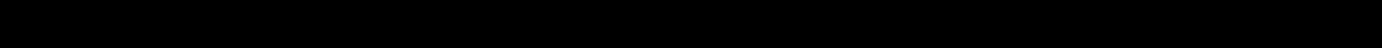


#### Q: Identify the input features X and the target y.

From `Diabetes_Understanding_the_Dataset.docx`, we know that the input X is the 21 features and the target y is `Diabetes_binary`, where 0 = no diabetes & 1 = prediabetes or diabetes.


#### Q: Explain what class 0 and class 1 mean.

As mentioned, class 0 means the respondent has no diabetes, and class 1 means they have _prediabetes_ or _diabetes_. We also see that _prediabetes_ and _diabetes_ both are in class 1, so we can't tell those apart ;(

#### Q: Check the number and proportion of observations in each class.

In [12]:
df = pd.read_csv("Data/diabetes.csv")
target = "Diabetes_binary"

X = df.drop(columns=target)
y = df[target]

print("Shape:", df.shape)
display(df.head())

Shape: (253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [21]:
print("Number of observations:")
display(df[target].value_counts()) # number
print("--------------------------")
print("Proportion of observations:")
display(df[target].value_counts(normalize=True)) # proportion

Number of observations:


Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

--------------------------
Proportion of observations:


Diabetes_binary
0.0    0.860667
1.0    0.139333
Name: proportion, dtype: float64

We see there are 218,334 respondents in class 0 (86.1 %) **don't have diabetes**, and 35,346 in class 1 (13.9 %) either **have _diabetes_ or _prediabetes_**

#### Q: Choose three features of different types and briefly explain what their values mean. Use the Understanding the Dataset guide.

From the dataset guide, section 3 "Complete feature guide", let's pick features `BMI`, `HighBP`, `Age`:

| Feature | Type | What the values mean                                               |
|:---|:---|:-------------------------------------------------------------------|
| `BMI` | Numerical | A measured value, so BMI = 30 is an actual BMI of 30               |
| `HighBP` | Binary | 0 = no and 1 = yes, respondent has high blood pressure             |
| `Age` | Ordinal | An age group, so Age = 9 means 60–64 years old and not 9 years old |

So a number in the CSV isn't always an amount, and we have to check what it means before we use it.

---
## Step 2 - Explore the data (Kristian)


#### For numerical features, examine their distributions and compare them between the two target classes.

The only numerical features listed in "3. Complete feature guide" are `BMI`, `MentHlth` & `PhysHlth`:

In [23]:
numerical_features = ["BMI", "MentHlth", "PhysHlth"]

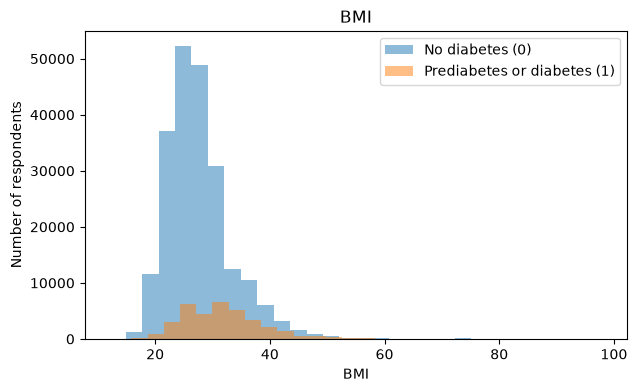

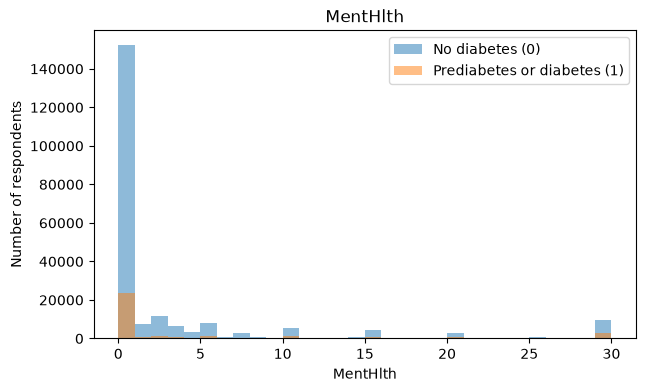

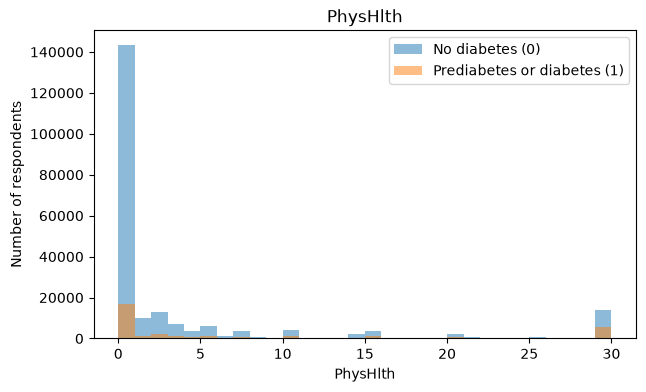

In [25]:
for feature in numerical_features:
    plt.figure(figsize=(7, 4))

    df.loc[df[target] == 0, feature].plot(
        kind="hist", bins=30, alpha=0.5, label="No diabetes (0)"
    )
    df.loc[df[target] == 1, feature].plot(
        kind="hist", bins=30, alpha=0.5, label="Prediabetes or diabetes (1)"
    )

    plt.xlabel(feature)
    plt.ylabel("Number of respondents")
    plt.title(feature)
    plt.legend()
    plt.show()

**What do we see?**

The histograms show that most respondents have a BMI between 20 and 40, and that most have 0 days of poor mental and physical health. Class 1 is quite small compared to class 0, but it looks like class 1 for `BMI` has a peak a bit further to the right, so they tend to have a higher BMI. For `MentHlth` and `PhysHlth` both classes have most respondents at 0 days.

#### For binary categorical features, examine counts/proportions and compare the proportion of Diabetes_binary across the two categories.

First, let's list every binary feature from the dataset guide:

In [29]:
binary_features = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "DiffWalk",
    "Sex"
]

Now, let's look at the proportion with diabetes when each binary feature is 0 and when it's 1, using a crosstab for each feature:

,0.0,1.0
HighBP,0.060352,0.244457
HighChol,0.079814,0.220149
CholCheck,0.025449,0.143749
Smoker,0.120553,0.162929
Stroke,0.131798,0.317528
HeartDiseaseorAttack,0.119537,0.329720
PhysActivity,0.211448,0.116127
Fruits,0.157929,0.128609
Veggies,0.179979,0.129887
HvyAlcoholConsump,0.144154,0.058361


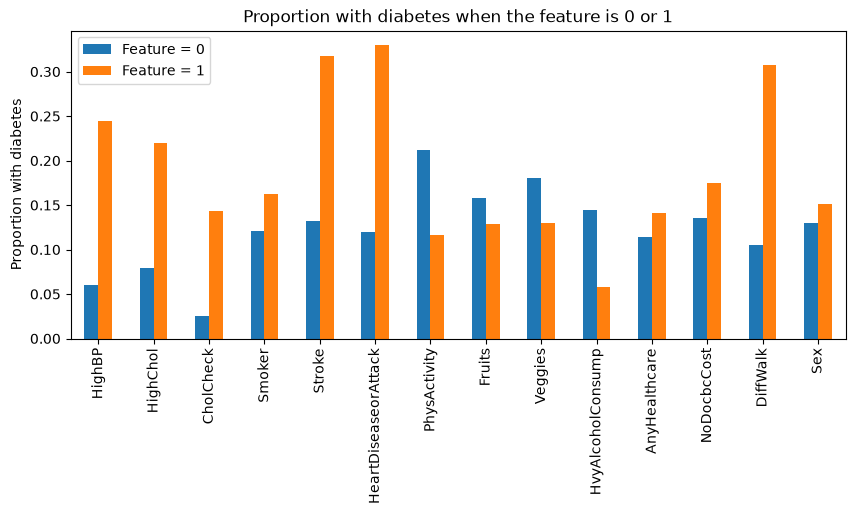

In [33]:
binary_results = {}

for feature in binary_features:
    proportions = pd.crosstab(df[feature], df[target], normalize="index")
    binary_results[feature] = proportions[1.0]

binary_results = pd.DataFrame(binary_results).T
display(binary_results)

binary_results.plot(kind="bar", figsize=(10, 4))
plt.ylabel("Proportion with diabetes")
plt.title("Proportion with diabetes when the feature is 0 or 1")
plt.legend(["Feature = 0", "Feature = 1"])
plt.show()

**What do we see?**

- `HighBP`, `CholCheck`, `HeartDiseaseorAttack` & `DiffWalk` really stand out as the biggest difference, the proportion is around 3-4 times higher when the feature is 1.
- `PhysActivity` and `HvyAlcoholConsump` go the other way, fewer people have diabetes when the feature is 1.
- `Smoker`, `AnyHealthcare`, `NoDocbcCost` & `Sex` show almost no difference.

Note that this is only a pattern in the data, and not the full picture. For example can we see that heavy drinkers have less diabetes, but that doesn't mean alcohol protects against diabetes.

#### For ordered categorical features, examine how the distribution or proportion of Diabetes_binary changes across the ordered categories.

We do the same as last time, but now for ordered (ordinal) features:

In [34]:
ordinal_features = ["GenHlth", "Age", "Education", "Income"]

Unlike the binary features, the ordinal features don't all have the same number of categories, so we can't put them in one table like last time. Instead we make one small plot for each feature:

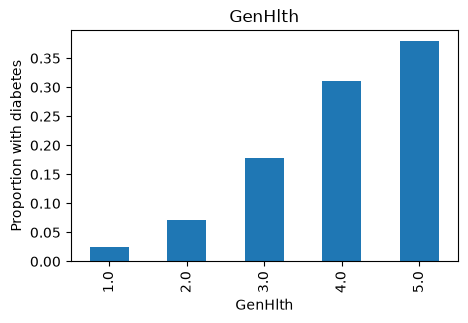

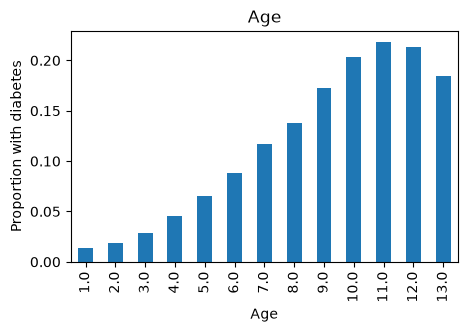

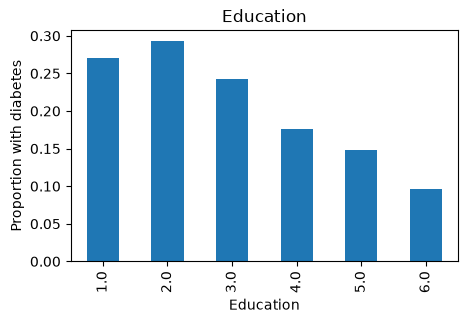

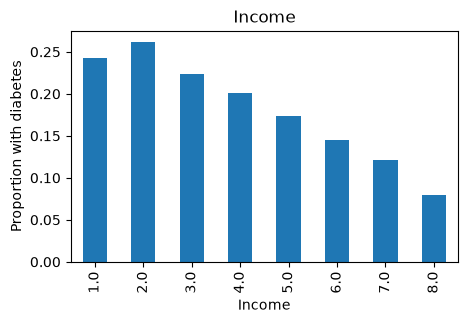

In [42]:
for feature in ordinal_features:
    proportions = pd.crosstab(df[feature], df[target], normalize="index")

    proportions[1].plot(kind="bar", figsize=(5, 3))
    plt.ylabel("Proportion with diabetes")
    plt.title(feature)
    plt.show()

**What do we see?**

- `GenHlth`: the proportion with diabetes goes up with each step, from under 5 % for excellent health (1) to around 40 % for poor health (5).
- `Age`: the proportion goes up with age until about 70-74 (11), then it drops a bit for the oldest groups.
- `Education` & `Income`: the proportion goes down, so higher education and higher income have fewer with diabetes.

So all four ordinal features show a clear pattern across the categories, but again this is only a link and not cause and effect.

#### Explore all input features, but focus your detailed interpretation on the most informative or interesting results. You may use loops or functions where appropriate rather than repeating essentially identical code.

We have looked at all the (3 + 14 + 4) 21 input features above. The most interesting results are:

- `HvyAlcoholConsump`: heavy drinkers have fewer with diabetes, which is the opposite of what we might expect.
- `CholCheck`: those who have checked their cholesterol have more with diabetes... could be because people with diabetes see a doctor more often.
- `GenHlth`: the proportion of people with diabetes increases quite steadily the worse their health is.
- `Age`: diabetes amount goes up with age, but drops for ages 80+... maybe fewer with diabetes live that long (?).
- `Smoker`, `Sex` & `MentHlth` show almost no difference, even though we might expect smoking to matter.

#### For the results you discuss in detail, state the question, show appropriate evidence, explain what you observe, and explain what the evidence allows you to conclude and what it does not.

For `HvyAlcoholConsump` we wanted to see if heavy drinkers have more diabetes. The binary table shows the opposite, non-heavy drinkers have about 2-3 times more people with diabetes than heavy drinkers. So in this dataset heavy drinking is linked to fewer with diabetes, but we can't really say that alcohol prevents it. People with diabetes might just be told to stop drinking.

For `GenHlth`, people with poor health have more than 10 times more diabetes than those with excellent health, so this one looks really useful for the model. But that doesn't mean poor health causes diabetes, it might as well be the other way around.

#### Look for patterns such as differences between the two target classes, changes in the proportion of class 1 across categories, unusual distributions, and features that appear to have little relationship with the target.

Most of this has already been covered above, but one thing we haven't mentioned is that `MentHlth` & `PhysHlth` look a bit weird. Most people answer 0 days, but there are peaks at 5, 10, 15 and 30, probably because people like round numbers, and choose numbers like 5 or 15 instead of the exact number of days.

---
## Step 3 - Create TRAIN and TEST (Emilie)

#### Split X and y into TRAIN and TEST.

#### Use stratify=y so that TRAIN and TEST have approximately the same proportion of class 0 and class 1.

#### Keep TEST separate until evaluation. Do not balance or resample TEST.

---
## Step 4 - Prepare the features (Kristian)

#### Prepare the input features using the information in the Understanding the Dataset guide and the preprocessing methods introduced in the course. Your preprocessing choice should reflect whether a feature is numerical, binary categorical, or ordered categorical. Briefly justify how you represent each type.

#### There are no missing values in this dataset, so missing-value imputation is not required.

#### Use a Pipeline/ColumnTransformer where appropriate.

#### Anything learned from the data during preprocessing must be learned from TRAIN only and then applied to TEST.

---
## Step 5 - Train logicstic regression (David)

#### Use Logistic Regression, as introduced in the classification lecture. Fit the complete Pipeline using TRAIN.

#### Use model.predict(X_test) to obtain predicted classes.

#### Use model.predict_proba(X_test)[:, 1] to obtain predicted probabilities for class 1.

---
## Step 6 - Evaluate the model (David)

#### Evaluate the model on TEST: confusion matrix.

#### Evaluate the model on TEST: accuracy.

#### Evaluate the model on TEST: precision.

#### Evaluate the model on TEST: recall.

#### Evaluate the model on TEST: F1 score.

#### Explain what a false positive and a false negative mean for this diabetes classification problem. Do not judge the model from accuracy alone.

---
## Step 7 - Probability and threshold (Emilie)

#### Use the predicted probabilities from Logistic Regression to compare two decision thresholds: 0.50 and 0.40.

#### For each threshold, calculate the confusion matrix, precision and recall.

#### Compare the results. Explain what happened to false positives, false negatives, precision and recall.

#### Also explain what did NOT change when you changed only the threshold.

---
## Step 8 - Conclusion (Emilie)

#### Summarize the most important things you learned from the EDA and the Logistic Regression results.

#### Give at least two limitations of this analysis.

#### Do not interpret an association as evidence that one feature causes diabetes.